# Context: does more history help?
Decision 16 ended with "next: more context per example". How much context is there now? Each example carries the system prompt and **up to 6 previous turns** of the same session (mean 5.6 on `valid`, median 6). A turn is consecutive messages by the same person, each within 5 min of the previous one, merged into one; a session ends after 3 h of silence. Training used that fixed window of 6.

Here only the context changes, at prediction time: no retraining. Same 1,012 `valid` replies, with 1, 5, 6, 10 and 20 previous turns (fewer if the session has fewer), built by `build_context.py`. Model: the best lr 1e-5 checkpoint (`run1_5ep`, step 2500, 1.85 epochs, valid 3.418), and the base model without adapter as control.

- Main comparison: the 719 replies with at least 20 turns of history, so every N is measured on the same examples with the full window.
- N = 6 on all 1,012 must give back 3.418 (sanity check).

Caveat: the adapter was trained with 6 turns, so 10 and 20 are longer than anything it saw. If more context helps here, the real test is retraining with that window; if it doesn't, it may be the training, not the context.

_My prediction:_ performance should get noticeably worse with a single previous turn. As we add turns it should improve, roughly logarithmically: going from 1 to 5 should help a lot, and after that the gains should be marginal. If they aren't, it may be that more previous context simply helps, but it depends on the kind of conversation. Some conversations are short, or touch a topic for a moment and drop it; others keep developing over time. In those, more context can help give a better reply; in the short ones it won't. So it won't be a perfect curve, but in my head it looks something like a logarithm.

In [10]:
import json, math
import mlx.core as mx
from mlx_lm import load

MODELO = "mlx-community/Qwen2.5-0.5B-Instruct-4bit"
EJEMPLOS_TRAIN = 5404  # session train size; epoch = step * 4 / 5404

In [11]:
# Copied as is from Perplexity.ipynb
def nll_ejemplo(model, tokenizer, messages):
    full = tokenizer.apply_chat_template(messages)
    base_prompt = tokenizer.apply_chat_template(
        messages[:-1], add_generation_prompt=True)
    n_tokens = len(full) - len(base_prompt)
    logits = model(mx.array(full)[None])
    logits = logits[0, len(base_prompt)-1:len(full)-1]
    logits = logits.astype(mx.float32)
    logprobs = logits - mx.logsumexp(logits, axis=-1, keepdims=True)
    nll = 0
    for i in range(n_tokens):
        nll -= logprobs[i, full[len(base_prompt) + i]].item()
    mx.clear_cache()
    return (nll, n_tokens)

def medir(model, tokenizer, ruta):
    with open(ruta, "r") as f:
        ejemplos = [json.loads(line) for line in f if line.strip()]
    return [nll_ejemplo(model, tokenizer, e["messages"]) for e in ejemplos]

In [12]:
def resumen(resultados):
    nll = sum(r[0] for r in resultados)
    n = sum(r[1] for r in resultados)
    return nll / n

## Data
`data/dataset/context/`, from `uv run python build_context.py`. `valid_ctx6.jsonl` is byte-identical to `session/valid.jsonl`; `valid_meta.json` has, per example, how many turns its session has before the reply.

In [13]:
CONTEXTOS = [1, 5, 6, 10, 20]
DATOS = "../data/dataset/context"
ADAPTADOR = "../adapters/run1_5ep"
PASO = 2500  # best valid nll at lr 1e-5: 3.418 (results/checkpoints_lr1e-5.json)
REFERENCIA = 3.418

with open(f"{DATOS}/valid_meta.json") as f:
    meta = json.load(f)["examples"]
historia = [e["history"] for e in meta]
sesion = [e["session"] for e in meta]  # for the bootstrap by session
subconjunto = [i for i, h in enumerate(historia) if h >= max(CONTEXTOS)]
print(f"{len(historia)} examples, {len(subconjunto)} with at least {max(CONTEXTOS)} turns of history")

1012 examples, 719 with at least 20 turns of history


## Measure
One pass per N and model. Each result is the list of `(nll, tokens)` per example, so the subset is just a filter afterwards.

In [14]:
def medir_contextos(model, tokenizer, nombre):
    """nll_ejemplo on valid_ctx{N}.jsonl for every N; prints both means as each N finishes."""
    por_n = {}
    for n in CONTEXTOS:
        r = medir(model, tokenizer, f"{DATOS}/valid_ctx{n}.jsonl")
        por_n[n] = r
        print(f"{nombre} ctx {n:>2}: all {resumen(r):.3f} | >=20 history {resumen([r[i] for i in subconjunto]):.3f}")
    return por_n

In [15]:
model, tokenizer = load(MODELO, adapter_path=ADAPTADOR)
model.load_weights(f"{ADAPTADOR}/{PASO:07d}_adapters.safetensors", strict=False)
adaptado = medir_contextos(model, tokenizer, "run1_5ep@2500")

# Sanity check: N = 6 on all of valid is exactly what Checkpoints.ipynb measured.
assert abs(resumen(adaptado[6]) - REFERENCIA) < 0.005, resumen(adaptado[6])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

run1_5ep@2500 ctx  1: all 3.535 | >=20 history 3.606
run1_5ep@2500 ctx  5: all 3.425 | >=20 history 3.488
run1_5ep@2500 ctx  6: all 3.418 | >=20 history 3.480
run1_5ep@2500 ctx 10: all 3.403 | >=20 history 3.465
run1_5ep@2500 ctx 20: all 3.394 | >=20 history 3.454


In [16]:
model, tokenizer = load(MODELO)  # base, no adapter: the control
base = medir_contextos(model, tokenizer, "base")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

base ctx  1: all 4.897 | >=20 history 4.890
base ctx  5: all 4.386 | >=20 history 4.366
base ctx  6: all 4.356 | >=20 history 4.333
base ctx 10: all 4.251 | >=20 history 4.215
base ctx 20: all 4.146 | >=20 history 4.082


## Results

In [17]:
def medias(por_n, indices=None):
    return {n: resumen(r if indices is None else [r[i] for i in indices]) for n, r in por_n.items()}

resultados = {
    "source": "experiments/Context.ipynb",
    "model": MODELO,
    "adapter": f"{ADAPTADOR.removeprefix('../')}/{PASO:07d}_adapters.safetensors",
    "data": DATOS.removeprefix("../"),
    "n_all": len(historia),
    "n_subset": len(subconjunto),
    "subset_min_history": max(CONTEXTOS),
    "adapter_subset": medias(adaptado, subconjunto),
    "adapter_all": medias(adaptado),
    "base_subset": medias(base, subconjunto),
    "base_all": medias(base),
    # Per example, in valid_ctx{N}.jsonl order: [nll_sum, n_tokens]. Same targets for every N, so paired.
    "per_example": {"adapter": adaptado, "base": base},
}
with open("results/context_v1.json", "w") as f:
    json.dump(resultados, f, indent=2)

print(f"{'ctx':>4} {'adapter >=20':>12} {'base >=20':>10} {'adapter all':>12} {'base all':>9}")
for n in CONTEXTOS:
    print(f"{n:>4} {resultados['adapter_subset'][n]:>12.3f} {resultados['base_subset'][n]:>10.3f} "
          f"{resultados['adapter_all'][n]:>12.3f} {resultados['base_all'][n]:>9.3f}")

 ctx adapter >=20  base >=20  adapter all  base all
   1        3.606      4.890        3.535     4.897
   5        3.488      4.366        3.425     4.386
   6        3.480      4.333        3.418     4.356
  10        3.465      4.215        3.403     4.251
  20        3.454      4.082        3.394     4.146


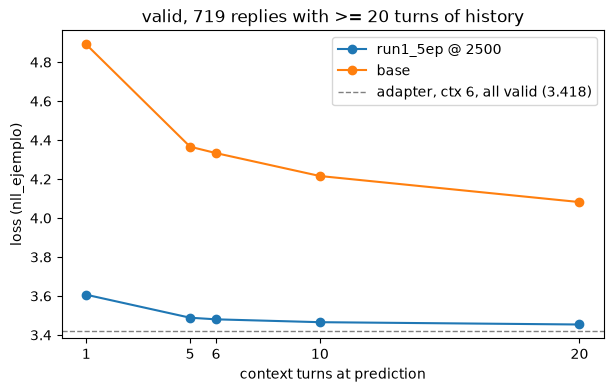

In [18]:
import matplotlib.pyplot as plt

fig, eje = plt.subplots(figsize=(7, 4))
eje.plot(CONTEXTOS, list(resultados["adapter_subset"].values()), marker="o", label="run1_5ep @ 2500")
eje.plot(CONTEXTOS, list(resultados["base_subset"].values()), marker="o", label="base")
eje.axhline(REFERENCIA, color="gray", linestyle="--", linewidth=1, label="adapter, ctx 6, all valid (3.418)")
eje.set_title(f"valid, {len(subconjunto)} replies with >= {max(CONTEXTOS)} turns of history")
eje.set_xlabel("context turns at prediction"); eje.set_ylabel("loss (nll_ejemplo)"); eje.set_xticks(CONTEXTOS); eje.legend()
plt.show()

## Is 20 turns really better than 6?
Paired: same replies, same tokens, only the context changes. For each model and set: token-weighted mean nll with 6 and 20 turns, the difference (20 − 6, negative = 20 is better), the share of replies whose per-token nll improves, and a 95% bootstrap CI of the difference. The bootstrap resamples sessions (1000, with replacement, seed 0), as in Perplexity.ipynb, because replies of the same session are not independent.

In [19]:
import random
import numpy as np

# Copied from Perplexity.ipynb
def por_sesion(resultados, etiquetas):
    sumas = {}
    for (nll, n), s in zip(resultados, etiquetas):
        if s not in sumas:
            sumas[s] = [0.0, 0]
        sumas[s][0] += nll
        sumas[s][1] += n
    return sumas

def perdida(sumas, elegidas):
    nll, n = 0.0, 0
    for s in elegidas:
        nll += sumas.get(s, [0.0, 0])[0]
        n += sumas.get(s, [0.0, 0])[1]
    return nll / n

def comparar(por_n, indices, antes=6, despues=20, repeticiones=1000):
    """Paired comparison of two context windows on the same examples."""
    r_antes = [por_n[antes][i] for i in indices]
    r_despues = [por_n[despues][i] for i in indices]
    etiquetas = [sesion[i] for i in indices]
    media_antes, media_despues = resumen(r_antes), resumen(r_despues)
    mejoran = np.mean([d[0] / d[1] < a[0] / a[1] for a, d in zip(r_antes, r_despues)])
    s_antes, s_despues = por_sesion(r_antes, etiquetas), por_sesion(r_despues, etiquetas)
    sesiones = sorted(s_antes)
    random.seed(0)
    diferencias = []
    for _ in range(repeticiones):
        elegidas = random.choices(sesiones, k=len(sesiones))
        diferencias.append(perdida(s_despues, elegidas) - perdida(s_antes, elegidas))
    bajo, alto = np.percentile(diferencias, [2.5, 97.5])
    return media_antes, media_despues, media_despues - media_antes, mejoran, bajo, alto, len(sesiones)

todos = list(range(len(historia)))
print(f"{'model':<8} {'set':<5} {'ctx6':>6} {'ctx20':>6} {'diff':>7} {'improve':>8} {'95% CI (sessions)':>20}")
for nombre, por_n in [("adapter", adaptado), ("base", base)]:
    for conjunto, indices in [("all", todos), (">=20", subconjunto)]:
        a, d, dif, mej, lo, hi, n_s = comparar(por_n, indices)
        print(f"{nombre:<8} {conjunto:<5} {a:>6.3f} {d:>6.3f} {dif:>+7.3f} {mej:>7.0%} "
              f"[{lo:+.3f}, {hi:+.3f}] ({n_s})")

model    set     ctx6  ctx20    diff  improve    95% CI (sessions)
adapter  all    3.418  3.394  -0.024     49% [-0.031, -0.014] (60)
adapter  >=20   3.480  3.454  -0.027     56% [-0.037, -0.012] (16)
base     all    4.356  4.146  -0.209     74% [-0.234, -0.141] (60)
base     >=20   4.333  4.082  -0.251     87% [-0.270, -0.205] (16)


### Conclusion

Valid, nll_ejemplo, best 1e-5 checkpoint (run1_5ep, step 2500), no retraining. Context changed only at prediction time.

| N turns | adapter (719, ≥20 turns of history) | base (719) | adapter (all 1012) | base (all) |
|---|---|---|---|---|
| 1 | 3.606 | 4.890 | 3.535 | 4.897 |
| 5 | 3.488 | 4.366 | 3.425 | 4.386 |
| 6 | 3.480 | 4.333 | 3.418 | 4.356 |
| 10 | 3.465 | 4.215 | 3.403 | 4.251 |
| 20 | 3.454 | 4.082 | 3.394 | 4.146 |

My prediction holds: going from 1 to 5 turns helps a lot (−0.12 on the 719), from 6 to 20 only −0.03. Roughly logarithmic.

The base model gains much more from context (4.33 → 4.08 from 6 to 20). With more context it picks up that this is a fast WhatsApp exchange with short messages, which is exactly what the adapter already learned in training. Context and fine-tuning partly do the same job: the gap between adapter and base goes from 1.28 with 1 turn to 0.63 with 20.

With 20 turns the adapter gets 3.394 on the full valid set, the first result below 3.418. It's small but not noise: the paired bootstrap by session (adapter, 20 vs 6 turns, all 1012) gives −0.024, 95% CI [−0.031, −0.014]. Also, the adapter never saw more than 6 turns in training. Next: retrain with a 20-turn window.